[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/prep/P5_exposure_blockage.ipynb)


# P5 — การสัมผัสภัย (ประชากร/สิ่งปลูกสร้าง GHSL) และการบังลำคลื่นเรดาร์

**สำหรับผู้ดูแลข้อมูล** — ต่อจาก P3/P4 (ใช้ footprint ของเส้นทาง) ไม่ต้องอ่าน UF

**ทำไมต้องมี**
1. **Exposure:** จำนวนบ้านเสียหาย = ความรุนแรงของภัย × สิ่งที่อยู่ในเส้นทางพายุ พายุแรงกลางทุ่งนาอาจไม่มีรายงานเลย บท 07 จึงต้องรู้ว่าพายุแต่ละลูกผ่านประชากรและสิ่งปลูกสร้างมากแค่ไหน
2. **การบังลำคลื่น:** ภูเขาบังมุมยกต่ำสุด (0.5°) ทำให้เรดาร์ "มองไม่เห็น" พายุหลังภูเขา แผนที่ความถี่จะต่ำเกินจริงในเซกเตอร์นั้น (บท 06 พบ cold spot ทิศตะวันตก)

**ข้อมูล:** GHSL R2023A ความละเอียด 1 km ปี 2020 (JRC, CC BY 4.0) — `GHS_BUILT_S` พื้นที่สิ่งปลูกสร้าง (m²/เซลล์) และ `GHS_POP` ประชากร (คน/เซลล์) · DEM Copernicus GLO-90 แบบ **ค่าสูงสุด** ในเซลล์ 1 km (ยอดเขาคือสิ่งที่บัง)

**การบังลำคลื่น (Bech et al. 2003):** ลำคลื่นหน้าตัดวงกลมรัศมี $a = r\tan(\theta_{bw}/2)$ ศูนย์กลางสูง $h(r)$ (รัศมีโลก 4/3) ให้ $y = z_{\text{terrain}} - h$

$$\text{BBF} = \frac{y\sqrt{a^2-y^2} + a^2\sin^{-1}(y/a) + \pi a^2/2}{\pi a^2}\quad (-a<y<a)$$

แล้วสะสมค่าสูงสุดตามระยะ (สิ่งที่บังใกล้บังไกลทั้งหมด)

| ผลลัพธ์ | เนื้อหา |
|---|---|
| `data/derived/exposure_1km.nc` | built_m2, pop, bbf_0p5, bbf_1p5, blocked (กริดเดียวกับ CAPPI) |
| `data/derived/district_exposure.csv` | ประชากร/สิ่งปลูกสร้างรายอำเภอ (ใช้ปรับจำนวนบ้านเสียหาย) |
| `data/derived/track_exposure_<tag>.csv` | ต่อเส้นทาง: pop_fp, built_fp_km2, bbf_fp_mean, frac_blocked, bbf_start |
| `data/derived/blockage_azimuth.csv` | BBF ตามมุม เทียบความถี่ ≥ 35 dBZ จากข้อมูลจริง |

In [1]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

Mounted at /content/drive
โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 8 core


In [2]:
import json, time, shutil, warnings
from pathlib import Path
from functools import partial
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mproc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M
s = load_settings()
M.setup_style()
OUT_ROOT = Path(os.environ.get("KKN_OUT_ROOT", s["radar_data"]["drive_derived_root"]))
N_WORKERS = os.cpu_count()
CTX = mproc.get_context("fork")

# ดึงผลของขั้นก่อนหน้าจาก Drive (Colab แยกเครื่องต่อ notebook — ดู utils/sync.py)
from utils import sync
sync.pull(OUT_ROOT)
s = load_settings()      # อ่านใหม่หลัง pull (พิกัดเรดาร์จริงจาก P0)

import rasterio
from utils import exposure as X, geo as G, data_io, analysis as A
from utils import data as D
DER = repo_path("data", "derived")
CACHE = OUT_ROOT / s["exposure"]["ghsl_cache_subdir"]
BL = s["blockage"]
key = sorted(repo_path("data", "days").glob("*/KKN_*_cappi_15min.nc")) or sorted((OUT_ROOT / "cappi").glob("KKN_*_cappi_15min.nc"))
_, meta = data_io.load_pcappi(str(key[0]))
print("กริด:", len(meta["y"]), "×", len(meta["x"]), "| GHSL cache:", CACHE)

sync.pull: /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/repo_mirror → /content/Teach_stormTracks_KKN_May2024_HID_doppler
  คัดลอก 0 ไฟล์ (0.0 MB)
กริด: 481 × 481 | GHSL cache: /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/ghsl


## 1. GHSL: พื้นที่สิ่งปลูกสร้างและประชากร → กริด 1 km ของเรดาร์

ดาวน์โหลด GHS_BUILT_S_E2020_GLOBE_R2023A_54009_1000_V1_0.zip ...
ดาวน์โหลด GHS_POP_E2020_GLOBE_R2023A_54009_1000_V1_0.zip ...
ในรัศมี 240 km: ประชากร 18.23 ล้านคน | สิ่งปลูกสร้าง 2142 km²
บันทึกรูป → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/figures/p5_ghsl.png / .pdf


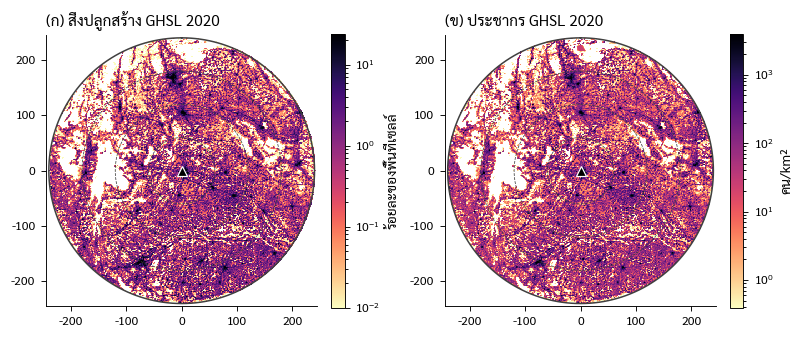

In [3]:
built = X.ghsl_to_grid(X.fetch_ghsl("built_s", CACHE), meta)      # m² ต่อเซลล์ 1 km²
pop = X.ghsl_to_grid(X.fetch_ghsl("pop", CACHE), meta)            # คนต่อเซลล์
cov = meta["coverage"]
print(f"ในรัศมี 240 km: ประชากร {np.nansum(pop[cov]) / 1e6:.2f} ล้านคน | สิ่งปลูกสร้าง {np.nansum(built[cov]) / 1e6:.0f} km²")
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.4), layout="constrained")
for ax, (g, ttl, lab) in zip(axs, [(built / 1e4, "(ก) สิ่งปลูกสร้าง GHSL 2020", "ร้อยละของพื้นที่เซลล์"),
                                   (pop, "(ข) ประชากร GHSL 2020", "คน/km²")]):
    im = A.show_grid(ax, np.where(cov, g, np.nan), meta, cmap="magma_r",
                     norm=plt.matplotlib.colors.LogNorm(max(np.nanpercentile(g[g > 0], 5), 1e-2), np.nanpercentile(g, 99.9)))
    M.add_range_rings(ax, s, label=False, name=False); ax.set_aspect("equal"); ax.set_xlim(-245, 245); ax.set_ylim(-245, 245)
    ax.set_title(ttl, loc="left"); fig.colorbar(im, ax=ax, shrink=0.75, label=lab)
M.savefig(fig, "p5_ghsl", outdir=OUT_ROOT / "figures"); plt.show()

## 2. การบังลำคลื่น (beam blockage)

ใช้ DEM **ค่าสูงสุด** ในเซลล์ 1 km (สร้างจาก Copernicus ครั้งแรก ~3 นาที) ถ้าสร้างไม่ได้จะใช้ DEM ค่าเฉลี่ยใน repo (ประเมินการบังต่ำกว่าจริงเล็กน้อย)

In [4]:
dem_max = repo_path(BL["dem_max"])
if not dem_max.exists():
    try:
        G.build_dem(s, out=dem_max, resampling="max")
    except Exception as e:
        print("สร้าง DEM ค่าสูงสุดไม่ได้:", e, "→ ใช้ DEM ค่าเฉลี่ย")
dem_path = dem_max if dem_max.exists() else repo_path(s["dem"]["out"])
with rasterio.open(dem_path) as f:
    dem, dtr = f.read(1).astype(float), f.transform
alt = s["radar"]["alt_m"]
BBF = {}
for e in (BL["elev_deg"], 1.5):
    az, r, b = X.beam_blockage(dem, dtr, alt, e, BL["beamwidth_deg"])
    BBF[e] = X.polar_to_grid(az, r, b, meta)
    print(f"มุมยก {e}°: BBF สะสมสูงสุด {np.nanmax(b):.2f} | พื้นที่ BBF ≥ {BL['threshold_bbf']}: "
          f"{np.nansum(BBF[e] >= BL['threshold_bbf'])} km² ({100 * np.nanmean(BBF[e][cov] >= BL['threshold_bbf']):.1f}% ของรัศมี) | DEM: {dem_path.name}")
blocked = (BBF[BL["elev_deg"]] >= BL["threshold_bbf"]) & cov

บันทึก DEM 521×521 จาก 30 ไทล์ → /content/Teach_stormTracks_KKN_May2024_HID_doppler/data/gis/dem_kkn_1km_max.tif
มุมยก 0.5°: BBF สะสมสูงสุด 0.75 | พื้นที่ BBF ≥ 0.25: 17564 km² (9.7% ของรัศมี) | DEM: dem_kkn_1km_max.tif
มุมยก 1.5°: BBF สะสมสูงสุด 0.00 | พื้นที่ BBF ≥ 0.25: 0 km² (0.0% ของรัศมี) | DEM: dem_kkn_1km_max.tif


บันทึกรูป → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/figures/p5_blockage_azimuth.png / .pdf


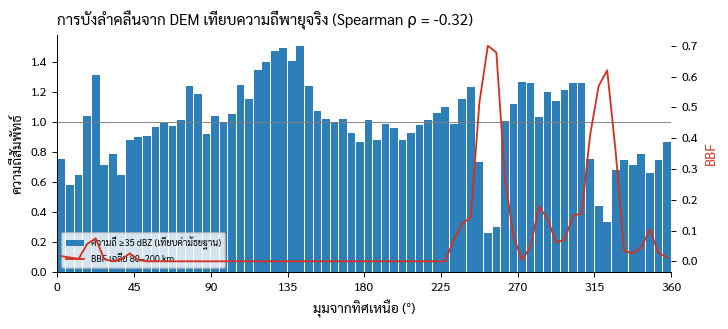

In [5]:
# ตรวจกับข้อมูลจริง: ความถี่ ≥ 35 dBZ ตามมุม (ช่วง 80–200 km) ควรต่ำในมุมที่ BBF สูง
MS = xr.open_dataset(DER / "monthly_summary_1km.nc")
prof = X.azimuth_profile(MS["freq_ge35_pct"].values, meta, bin_deg=5)
Xg, Yg = np.meshgrid(meta["x"] / 1e3, meta["y"] / 1e3)
AZ, RR = np.degrees(np.arctan2(Xg, Yg)) % 360, np.hypot(Xg, Yg)
mm = (RR >= 80) & (RR <= 200)
bb = pd.Series(BBF[BL["elev_deg"]][mm]).groupby((AZ[mm] // 5 * 5).astype(int)).mean()
AZT = pd.DataFrame({"az_deg": prof.index, "freq35_relative": prof.values, "bbf_mean_80_200km": bb.reindex(prof.index).values})
AZT.to_csv(DER / "blockage_azimuth.csv", index=False)
rho = AZT[["freq35_relative", "bbf_mean_80_200km"]].corr(method="spearman").iloc[0, 1]
fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.bar(AZT["az_deg"] + 2.5, AZT["freq35_relative"], width=4.5, color="#2c7fb8", label="ความถี่ ≥35 dBZ (เทียบค่ามัธยฐาน)")
ax.axhline(1, color="0.5", lw=0.6)
ax2 = ax.twinx(); ax2.plot(AZT["az_deg"] + 2.5, AZT["bbf_mean_80_200km"], "-", color="#d7301f", lw=1.2, label="BBF เฉลี่ย 80–200 km")
ax.set_xlim(0, 360); ax.set_xticks(range(0, 361, 45)); ax.set_xlabel("มุมจากทิศเหนือ (°)")
ax.set_ylabel("ความถี่สัมพัทธ์"); ax2.set_ylabel("BBF", color="#d7301f")
ax.set_title(f"การบังลำคลื่นจาก DEM เทียบความถี่พายุจริง (Spearman ρ = {rho:.2f})", loc="left")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=6, loc="lower left")
M.savefig(fig, "p5_blockage_azimuth", outdir=OUT_ROOT / "figures"); plt.show()

บันทึกรูป → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/figures/p5_blockage_map.png / .pdf


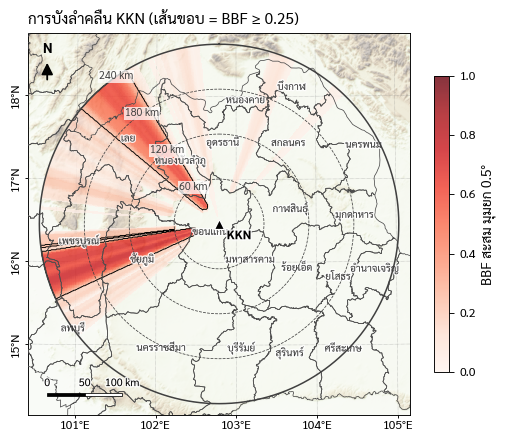

In [6]:
fig, ax = plt.subplots(figsize=(5.6, 5.0))
M.base_map(ax, s, dem=G.load_dem(s, build_if_missing=False), dem_alpha=0.5)
im = A.show_grid(ax, np.where(BBF[BL["elev_deg"]] > 0.02, BBF[BL["elev_deg"]], np.nan), meta, cmap="Reds", vmin=0, vmax=1, alpha=0.8, zorder=5)
fig.colorbar(im, ax=ax, shrink=0.7, label=f"BBF สะสม มุมยก {BL['elev_deg']}°")
ax.set_title(f"การบังลำคลื่น KKN (เส้นขอบ = BBF ≥ {BL['threshold_bbf']})", loc="left")
ax.contour(meta["x"] / 1e3, meta["y"] / 1e3, blocked.astype(float), levels=[0.5], colors="k", linewidths=0.6, zorder=6)
M.savefig(fig, "p5_blockage_map", outdir=OUT_ROOT / "figures"); plt.show()

## 3. บันทึกกริด และสรุปรายอำเภอ

In [7]:
from utils import derived_io as DIO
grids = {"built_m2": built, "pop": pop, "bbf_0p5": BBF[BL["elev_deg"]], "bbf_1p5": BBF[1.5], "blocked": blocked.astype(np.float32)}
DIO.write_grids_2d(DER / "exposure_1km.nc", {k: np.where(cov, v, np.nan) for k, v in grids.items()}, meta,
                   {"ghsl": X.GHSL_CITATION, "dem_for_blockage": dem_path.name, "beamwidth_deg": BL["beamwidth_deg"],
                    "blockage_threshold": BL["threshold_bbf"], "method": "Bech et al. (2003) cumulative BBF"})
amp = G.load_admin("district", s).dissolve(by="amp_code", as_index=False, aggfunc="first")
ones = np.where(cov, 1.0, 0.0)
dex = pd.DataFrame({"amp_code": amp["amp_code"], "pro_th": amp["pro_th"], "amp_th": amp["amp_th"]})
for col, g, f in [("pop", pop, 1), ("built_km2", built, 1e-6), ("area_in_radar_km2", ones, 1),
                  ("blocked_km2", blocked.astype(float), 1)]:
    dex[col] = X.zonal_sum_polygons(g, meta, amp, "amp_code").reindex(amp["amp_code"]).values * f
dex["frac_blocked"] = dex["blocked_km2"] / dex["area_in_radar_km2"].replace(0, np.nan)
dex.to_csv(DER / "district_exposure.csv", index=False)
dex.sort_values("pop", ascending=False).head(8).round(2)

,amp_code,pro_th,amp_th,pop,built_km2,area_in_radar_km2,blocked_km2,frac_blocked
0,1601,ลพบุรี,เมืองลพบุรี,504346.72,27.93,0.0,0.0,NaN
201,4001,ขอนแก่น,เมืองขอนแก่น,472046.53,42.65,972.0,0.0,0.00
39,3001,นครราชสีมา,เมืองนครราชสีมา,426236.52,53.20,761.0,0.0,0.00
133,3401,อุบลราชธานี,เมืองอุบลราชธานี,286716.43,24.70,29.0,0.0,0.00
227,4101,อุดรธานี,เมืองอุดรธานี,284123.62,39.60,1120.0,0.0,0.00
71,3101,บุรีรัมย์,เมืองบุรีรัมย์,220977.20,22.74,830.0,0.0,0.00
407,6701,เพชรบูรณ์,เมืองเพชรบูรณ์,209286.06,20.97,2248.0,352.0,0.16
321,4701,สกลนคร,เมืองสกลนคร,206617.01,19.98,938.0,0.0,0.00


## 4. Exposure และการบังของแต่ละเส้นทาง (ทุก Δt)

In [8]:
bbf = np.nan_to_num(BBF[BL["elev_deg"]])
for tag in s["tracking"]["tags"]:
    FP = D.table(f"footprints_{tag}.gpkg")
    T = D.table(f"tracks_{tag}.csv")
    t0 = time.time()
    out = pd.DataFrame({"uid": FP["uid"]})
    area = X.zonal_sum_polygons(ones, meta, FP, "uid")
    out["pop_fp"] = X.zonal_sum_polygons(pop, meta, FP, "uid").values
    out["built_fp_km2"] = X.zonal_sum_polygons(built, meta, FP, "uid").values / 1e6
    out["bbf_fp_mean"] = X.zonal_sum_polygons(bbf, meta, FP, "uid").values / area.replace(0, np.nan).values
    out["frac_blocked"] = X.zonal_sum_polygons(blocked.astype(float), meta, FP, "uid").values / area.replace(0, np.nan).values
    # BBF ที่จุดเริ่มของเส้นทาง (จุดกำเนิดในเขตที่ถูกบังอาจเป็นผลของการมองไม่เห็นช่วงต้น)
    C = D.table(f"cells_{tag}.csv.gz")
    first = C.sort_values("time").groupby("uid").first()
    ci = np.clip(np.round((first["cx"] - meta["x"][0]) / 1000).astype(int), 0, len(meta["x"]) - 1)
    ri = np.clip(np.round((meta["y"][0] - first["cy"]) / 1000).astype(int), 0, len(meta["y"]) - 1)
    out = out.merge(pd.DataFrame({"uid": first.index, "bbf_start": bbf[ri, ci]}), on="uid", how="left")
    out.to_csv(DER / f"track_exposure_{tag}.csv", index=False, float_format="%.5g")
    print(f"{tag}: {len(out)} เส้นทาง | มัธยฐาน pop_fp {out['pop_fp'].median():.0f} คน | "
          f"ผ่านเขตถูกบัง > 25% ของ footprint: {(out['frac_blocked'] > 0.25).mean():.1%} | {time.time() - t0:.0f} วินาที")

15min: 4423 เส้นทาง | มัธยฐาน pop_fp 7549 คน | ผ่านเขตถูกบัง > 25% ของ footprint: 7.3% | 19 วินาที
10min_linZ: 5097 เส้นทาง | มัธยฐาน pop_fp 6626 คน | ผ่านเขตถูกบัง > 25% ของ footprint: 7.4% | 21 วินาที
05min_linZ: 7074 เส้นทาง | มัธยฐาน pop_fp 5683 คน | ผ่านเขตถูกบัง > 25% ของ footprint: 7.4% | 28 วินาที


## บันทึกผลเข้า Drive และ (เลือกได้) commit ขึ้น GitHub

`sync.push` เก็บไฟล์ที่จะเข้า repo ไว้ใน `KKN_derived_v1/repo_mirror/` notebook ถัดไป (เครื่องใหม่) จะดึงไปใช้เองตอนเริ่ม **รันเซลล์นี้ทุกครั้งก่อนปิด runtime**

ถ้าต้องการ commit ทันที ตั้ง `COMMIT = True` (ต้องมี secret `KKN_commit` = fine-grained token ของ repo นี้ สิทธิ์ Contents: Read and write) ตั้ง `dry_run=True` เพื่อดูรายการไฟล์ก่อน — ฟังก์ชันไม่พิมพ์ token ออกมา

In [11]:
sync.push(OUT_ROOT)
COMMIT = False
if COMMIT:
    sync.git_push("P5: GHSL exposure, beam blockage, track exposure", dry_run=False)

sync.push: /content/Teach_stormTracks_KKN_May2024_HID_doppler → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/repo_mirror
  คัดลอก 0 ไฟล์ (0.0 MB)


**ขั้นต่อไป:** บท 07 — เปรียบเทียบพายุที่ทำความเสียหาย (แยกระดับ) กับพายุในวันที่ไม่มีรายงาน